# Does late delivery hurt customer satisfaction?

**Business question.** Olist promises every customer an estimated delivery date at checkout. Does missing that date
affect review scores, by how much, and what else drives a bad review?

**Data.** `analytics.order_review_features` in the PostgreSQL warehouse (built by `etl/load_warehouse.py`).
One row per order that was delivered **and** reviewed. For the 547 orders with more than one review, the scores are averaged.

| Method | Question it answers |
|---|---|
| Welch's t-test (+ Mann-Whitney U) | Is the average review score different for late vs on-time orders? |
| Chi-squared test of independence | Is getting a 1-2 star review associated with late delivery? |
| OLS and logistic regression | Which order characteristics predict the score once the others are held constant? |

All tests use α = 0.05.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import statsmodels.formula.api as smf
from sqlalchemy import create_engine

# Connection uses the same PG* variables as the ETL; defaults match docker-compose.yml
url = "postgresql+psycopg://{u}:{p}@{h}:{port}/{db}".format(
    u=os.getenv("PGUSER", "olist"), p=os.getenv("PGPASSWORD", "olist_local"),
    h=os.getenv("PGHOST", "localhost"), port=os.getenv("PGPORT", "5434"), db=os.getenv("OLIST_DB", "olist"))
engine = create_engine(url)

df = pd.read_sql("SELECT * FROM analytics.order_review_features", engine)
for c in ["review_score", "delivery_days", "order_price", "order_freight"]:
    df[c] = df[c].astype(float)
df["delivery"] = np.where(df["is_late"], "Late", "On time")

# chart styling: thin marks, recessive axes, validated palette shared with the Power BI theme
BLUE, ORANGE, INK, MUTED, GRID = "#1F6FB2", "#F28C28", "#1F2A37", "#5B6675", "#E3E7ED"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
print(f"{len(df):,} delivered & reviewed orders")
df.head()

95,830 delivered & reviewed orders


,order_id,purchase_date,customer_state,customer_region,delivery_days,promised_days,days_vs_estimate,is_late,n_items,n_sellers,order_price,order_freight,review_score,is_negative_review,delivery
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09-13,RJ,Southeast,7.61,16,-9,False,1,1,58.90,13.29,5.0,False,On time
1,00018f77f2f0320c557190d7a144bdd3,2017-04-26,SP,Southeast,16.22,19,-3,False,1,1,239.90,19.93,4.0,False,On time
2,00024acbcdf0a6daa1e931b038114c75,2018-08-08,SP,Southeast,6.15,12,-6,False,1,1,12.99,12.79,4.0,False,On time
3,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04,SP,Southeast,25.11,41,-16,False,1,1,199.90,18.14,5.0,False,On time
4,000576fe39319847cbb9d288c5617fa6,2018-07-04,SP,Southeast,5.08,21,-16,False,1,1,810.00,70.75,5.0,False,On time


## 1. Descriptive look

In [2]:
summary = (df.groupby("delivery")["review_score"]
             .agg(orders="size", mean_score="mean", median_score="median", std="std")
             .round(3))
summary["share_of_orders"] = (summary["orders"] / summary["orders"].sum()).round(3)
summary

,orders,mean_score,median_score,std,share_of_orders
delivery,,,,,
Late,6382,2.272,1.0,1.571,0.067
On time,89448,4.290,5.0,1.148,0.933


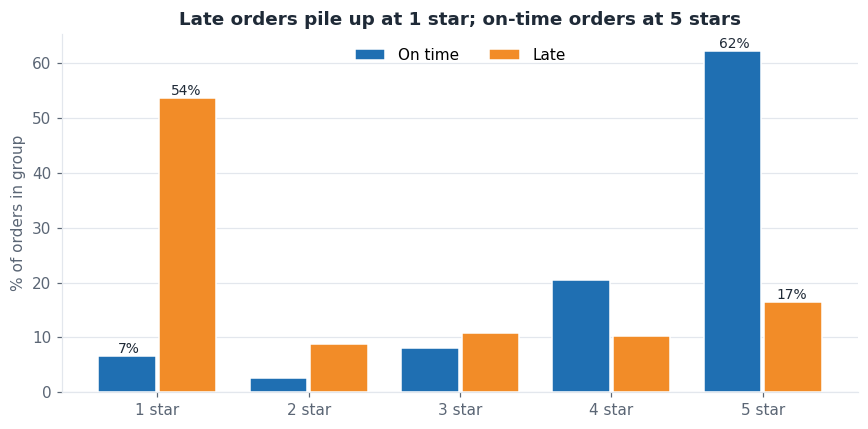

delivery,Late,On time
review_score,,
1,53.7,6.6
2,8.7,2.7
3,10.8,8.1
4,10.2,20.5
5,16.5,62.2


In [3]:
dist = (pd.crosstab(df["delivery"], df["review_score"].round().astype(int), normalize="index") * 100).T

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(dist.index))
w = 0.38
ax.bar(x - w / 2 - 0.01, dist["On time"], w, color=BLUE, label="On time", edgecolor="white", linewidth=1)
ax.bar(x + w / 2 + 0.01, dist["Late"], w, color=ORANGE, label="Late", edgecolor="white", linewidth=1)
ax.set_xticks(x, [f"{s} star" for s in dist.index])
ax.set_ylabel("% of orders in group")
ax.set_title("Late orders pile up at 1 star; on-time orders at 5 stars")
ax.legend(loc="upper center", ncol=2)
for s in (1, 5):
    i = list(dist.index).index(s)
    ax.annotate(f"{dist.loc[s, 'Late']:.0f}%", (x[i] + w / 2, dist.loc[s, "Late"]), ha="center", va="bottom", color=INK, fontsize=9)
    ax.annotate(f"{dist.loc[s, 'On time']:.0f}%", (x[i] - w / 2, dist.loc[s, "On time"]), ha="center", va="bottom", color=INK, fontsize=9)
plt.tight_layout(); plt.show()
dist.round(1)

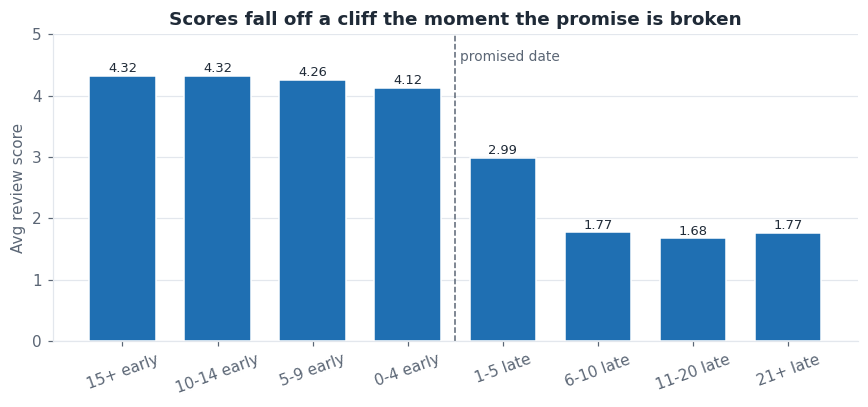

,mean,size
gap,,
15+ early,4.32,34776
10-14 early,4.32,26752
5-9 early,4.26,20032
0-4 early,4.12,7888
1-5 late,2.99,2722
6-10 late,1.77,1634
11-20 late,1.68,1262
21+ late,1.77,764


In [4]:
# Dose-response: does it matter *how* late (or early) the order is?
bins = [-np.inf, -15, -10, -5, 0, 5, 10, 20, np.inf]
labels = ["15+ early", "10-14 early", "5-9 early", "0-4 early", "1-5 late", "6-10 late", "11-20 late", "21+ late"]
by_gap = (df.assign(gap=pd.cut(df["days_vs_estimate"], bins=bins, labels=labels))
            .groupby("gap", observed=True)["review_score"].agg(["mean", "size"]))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(range(len(by_gap)), by_gap["mean"], 0.7, color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(3.5, color=MUTED, linestyle="--", linewidth=1)
ax.text(3.55, 4.75, "promised date", color=MUTED, fontsize=9, va="top")
ax.set_xticks(range(len(by_gap)), by_gap.index, rotation=20)
ax.set_ylim(0, 5); ax.set_ylabel("Avg review score")
ax.set_title("Scores fall off a cliff the moment the promise is broken")
for i, v in enumerate(by_gap["mean"]):
    ax.text(i, v + 0.06, f"{v:.2f}", ha="center", fontsize=8.5, color=INK)
plt.tight_layout(); plt.show()
by_gap.round(2)

Arriving early barely changes the score (about 4.3). As soon as an order misses its promised date, the average falls
to about 3.0, and past five days late it is below 2. This step shape is the first sign that customers judge
**the broken promise**, not just the wait.

## 2. Welch's two-sample t-test

* **H₀:** mean review score is the same for late and on-time orders.
* **H₁:** the means differ (two-sided).

Welch's version is used because the two groups have very different sizes and variances. Review scores are ordinal
(1-5), so a Mann-Whitney U test is run as a non-parametric robustness check. With n ≈ 96k, the t-test's normality
assumption is covered by the central limit theorem.

In [5]:
late = df.loc[df["is_late"], "review_score"]
on_time = df.loc[~df["is_late"], "review_score"]

t = st.ttest_ind(late, on_time, equal_var=False)
diff = late.mean() - on_time.mean()
ci = t.confidence_interval(0.95)
pooled_sd = np.sqrt(((late.size - 1) * late.var() + (on_time.size - 1) * on_time.var()) / (late.size + on_time.size - 2))
cohens_d = diff / pooled_sd
mw = st.mannwhitneyu(late, on_time, alternative="two-sided")

pd.Series({
    "mean (late)": late.mean(), "mean (on time)": on_time.mean(),
    "difference": diff, "95% CI low": ci.low, "95% CI high": ci.high,
    "t statistic": t.statistic, "Welch df": t.df, "p-value": t.pvalue,
    "Cohen's d": cohens_d, "Mann-Whitney p-value": mw.pvalue,
}).round(4)

mean (late)                2.2719
mean (on time)             4.2904
difference                -2.0185
95% CI low                -2.0578
95% CI high               -1.9792
t statistic             -100.7448
Welch df                6875.9047
p-value                    0.0000
Cohen's d                 -1.7092
Mann-Whitney p-value       0.0000
dtype: float64

**Result.** Late orders score about **2.0 points lower** on a 5-point scale (95% CI shown above), with p < 0.001.
Cohen's d is about −1.7, a *very large* effect by conventional thresholds (0.8 counts as large). The Mann-Whitney test
agrees, so the result doesn't depend on treating the scores as interval data. **Reject H₀.**

## 3. Chi-squared test of independence

* **H₀:** receiving a negative review (1-2 stars) is independent of whether the order was late.
* **H₁:** the two are associated.

In [6]:
table = pd.crosstab(df["delivery"], df["is_negative_review"].map({True: "Negative (1-2★)", False: "Not negative"}))
chi = st.chi2_contingency(table)

p_neg = table["Negative (1-2★)"] / table.sum(axis=1)
relative_risk = p_neg["Late"] / p_neg["On time"]
cramers_v = np.sqrt(chi.statistic / (table.values.sum() * (min(table.shape) - 1)))

display(table)
pd.Series({
    "chi-squared": chi.statistic, "dof": chi.dof, "p-value": chi.pvalue,
    "min expected count": chi.expected_freq.min(),
    "P(negative | late)": p_neg["Late"], "P(negative | on time)": p_neg["On time"],
    "relative risk": relative_risk, "Cramér's V": cramers_v,
}).round(4)

is_negative_review,Negative (1-2★),Not negative
delivery,,
Late,3979,2403
On time,8261,81187


chi-squared              15077.7380
dof                          1.0000
p-value                      0.0000
min expected count         815.1485
P(negative | late)           0.6235
P(negative | on time)        0.0924
relative risk                6.7508
Cramér's V                   0.3967
dtype: float64

**Result.** Every expected cell count is far above 5, so the test is valid. The association is highly significant
(p < 0.001), and Cramér's V ≈ 0.4 means a moderate-to-strong association. In plain terms, **a late order is about
7× more likely to get a 1-2 star review** (62% vs 9%). **Reject H₀.**

## 4. Regression: what drives the score once everything else is held constant?

**Model 1** uses the three drivers from the brief: delivery time, freight and price.
**Model 2** adds whether the promise was broken (`is_late`) and basket complexity (`n_items`, `n_sellers`).
An order with several sellers ships as several parcels.

Standard errors are heteroskedasticity-robust (HC3), because residuals of a bounded 1-5 score are not constant-variance.

In [7]:
m1 = smf.ols("review_score ~ delivery_days + order_freight + order_price", data=df).fit(cov_type="HC3")
m2 = smf.ols("review_score ~ delivery_days + is_late + order_freight + order_price + n_items + n_sellers",
             data=df).fit(cov_type="HC3")

def tidy(m):
    return pd.DataFrame({"coef": m.params, "ci_low": m.conf_int()[0], "ci_high": m.conf_int()[1],
                         "p_value": m.pvalues}).round(4)

print(f"Model 1  R² = {m1.rsquared:.3f}   n = {int(m1.nobs):,}")
display(tidy(m1))
print(f"Model 2  R² = {m2.rsquared:.3f}   adj. R² = {m2.rsquared_adj:.3f}")
display(tidy(m2))

Model 1  R² = 0.113   n = 95,830


,coef,ci_low,ci_high,p_value
Intercept,4.7621,4.7405,4.7838,0.0000
delivery_days,-0.0446,-0.0463,-0.0429,0.0000
order_freight,-0.0020,-0.0027,-0.0014,0.0000
order_price,-0.0000,-0.0001,0.0000,0.5154


Model 2  R² = 0.196   adj. R² = 0.196


,coef,ci_low,ci_high,p_value
Intercept,5.8899,5.7998,5.9801,0.0000
is_late[T.True],-1.5418,-1.5937,-1.4898,0.0000
delivery_days,-0.0219,-0.0236,-0.0202,0.0000
order_freight,0.0004,-0.0001,0.0009,0.1521
order_price,-0.0000,-0.0001,0.0000,0.3536
n_items,-0.2504,-0.2736,-0.2272,0.0000
n_sellers,-1.0628,-1.1531,-0.9726,0.0000


**Reading the coefficients**

* **Model 1.** Each extra day of delivery costs about **0.045 stars**, so a 10-day-slower order scores about 0.45 lower.
  Freight has a small negative effect. Price is not significant (p ≈ 0.5): customers don't rate expensive orders differently.
* **Model 2.** With lateness in the model, **breaking the promise costs about 1.5 stars on its own**, on top of
  0.02 stars per day of waiting. Freight is no longer significant. Its effect in Model 1 came from distance and
  delivery time, which it is correlated with (confounding).
* **Basket complexity matters.** Each additional seller in an order costs about **1 star**. Multi-seller orders
  arrive as separate shipments and are a clear operational pain point.
* R² rises from about 0.11 to 0.20. Most of the variation in reviews comes from things not in the data
  (product quality, expectations), which is normal for individual-level satisfaction data.

In [8]:
# Robustness: logistic regression on the probability of a 1-2 star review, reported as odds ratios
logit = smf.logit("is_negative_review ~ delivery_days + is_late + order_freight + order_price + n_items + n_sellers",
                  data=df.assign(is_negative_review=df["is_negative_review"].astype(int))).fit(disp=False, cov_type="HC3")
odds = pd.DataFrame({"odds_ratio": np.exp(logit.params),
                     "ci_low": np.exp(logit.conf_int()[0]), "ci_high": np.exp(logit.conf_int()[1]),
                     "p_value": logit.pvalues}).round(3)
print(f"Pseudo R² = {logit.prsquared:.3f}")
odds

Pseudo R² = 0.172


,odds_ratio,ci_low,ci_high,p_value
Intercept,0.007,0.006,0.008,0.00
is_late[T.True],8.203,7.514,8.954,0.00
delivery_days,1.039,1.035,1.043,0.00
order_freight,0.999,0.998,1.000,0.13
order_price,1.000,1.000,1.000,0.00
n_items,1.628,1.558,1.701,0.00
n_sellers,5.127,4.494,5.849,0.00


The logistic model agrees with the OLS results. Holding everything else equal, a late order has roughly **8× the odds** of a 1-2 star
review (odds ratio shown above), and each extra seller multiplies the odds by about 5.

## 5. Conclusions and recommendations

1. **Late delivery is the strongest controllable driver of bad reviews.** It is significant in the t-test,
   the chi-squared test and both regressions, with a large effect size.
2. **The promise matters more than the speed.** Early orders score the same however early they are, and the drop
   happens right at the estimated date. *Recommendation:* set delivery estimates from route-level percentiles
   (for example the 90th percentile of past delivery times) rather than averages, especially for North and Northeast
   states, where delivery takes about 3× longer than in São Paulo.
3. **Multi-seller baskets are risky.** *Recommendation:* consolidate shipments, or show customers that items
   arrive separately at checkout.
4. **Price and freight don't drive reviews directly** once delivery is accounted for, so discounting is unlikely
   to fix satisfaction.

**Caveats.** This is observational data, so the coefficients describe associations, not proven causes. For example,
late orders may also be the ones with stock problems. Orders that were never reviewed (about 0.8%) and orders that were
never delivered are excluded. An A/B test of padded vs. unpadded delivery estimates would confirm whether there is a causal effect.